In [16]:
import os
import cv2
import numpy as np
from tqdm import tqdm
import torch.optim as optim
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
import json
import torchvision
from torchvision import transforms
from torchvision.utils import save_image, make_grid
from torch.utils.data import Subset, random_split
from glob import glob
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from PIL import Image
import pandas as pd
import shutil
from pycocotools import mask as coco_mask
import os
from glob import glob
import matplotlib.pyplot as plt

In [ ]:
#from google.colab import drive
#drive.mount('/content/drive')

In [17]:
!pip3 install torch torchvision transformers pillow


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: C:\Users\chenk\miniconda3\python.exe -m pip install --upgrade pip


In [ ]:
# import os

# from google.colab import drive
# drive.mount('/content/drive')

In [18]:
!git clone https://github.com/jasonfghx/retina_image.git

fatal: destination path 'retina_image' already exists and is not an empty directory.


In [28]:
from transformers import SegformerForSemanticSegmentation

NUM_CLASSES = 2  # 例：背景 + 目標

model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b1-finetuned-ade-512-512",
    num_labels=NUM_CLASSES,
    ignore_mismatched_sizes=True
)

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b1-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


In [104]:
from transformers import SegformerForSemanticSegmentation

NUM_CLASSES = 2  # 例：背景 + 目標

model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/mit-b5",
    num_labels=NUM_CLASSES,
    ignore_mismatched_sizes=True
)
# pamixsun/segformer_for_optic_disc_cup_segmentation
# nvidia/mit-b4
#  = 'nvidia/mit-b0'
#  'nvidia/mit-b1'
#  'nvidia/mit-b2'
#  'nvidia/mit-b3'

#  'nvidia/mit-b5'

Loading weights:   0%|          | 0/1156 [00:00<?, ?it/s]

SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b5
Key                                           | Status     | 
----------------------------------------------+------------+-
classifier.bias                               | UNEXPECTED | 
classifier.weight                             | UNEXPECTED | 
decode_head.linear_c.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.weight                 | MISSING    | 
decode_head.batch_norm.num_batches_tracked    | MISSING    | 
decode_head.classifier.weight                 | MISSING    | 
decode_head.classifier.bias                   | MISSING    | 
decode_head.linear_c.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.running_mean           | MISSING    | 
decode_head.linear_fuse.weight                | MISSING    | 
decode_head.batch_norm.bias                   | MISSING    | 
decode_head.batch_norm.running_var            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different ta

In [29]:
from torch.utils.data import Dataset
from PIL import Image
import os
import numpy as np
from transformers import SegformerImageProcessor
processor = SegformerImageProcessor.from_pretrained(
    "nvidia/mit-b5"
)
class SegDataset(Dataset):
    def __init__(self, img_dir, mask_dir):
        self.imgs = sorted(os.listdir(img_dir))
        self.img_dir = img_dir
        self.mask_dir = mask_dir

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        img = Image.open(
            os.path.join(self.img_dir, self.imgs[idx])
        ).convert("RGB")

        mask = Image.open(
            os.path.join(self.mask_dir, self.imgs[idx])
        ).convert("L")
        mask = np.array(mask)
        mask = (mask > 0).astype(np.uint8)
        inputs = processor(
            images=img,
            segmentation_maps=mask,
            return_tensors="pt"
        )

        return {
            "pixel_values": inputs["pixel_values"][0],
            "labels": inputs["labels"].squeeze(0)
        }


In [30]:
import cv2
import os
import numpy as np
os.makedirs('C:/Users/chenk/Desktop/segformer/retina_image/train')
os.makedirs('C:/Users/chenk/Desktop/segformer/retina_image/train/images')
os.makedirs('C:/Users/chenk/Desktop/segformer/retina_image/train/labels')

FileExistsError: [WinError 183] 當檔案已存在時，無法建立該檔案。: 'C:/Users/chenk/Desktop/segformer/retina_image/train'

In [31]:
add=glob("C:/Users/chenk/Desktop/segformer/retina_image/s1/images01_png/*")
for i in add[:]:
    image = cv2.imread(i)
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(clipLimit=10.0, tileGridSize=(8,8))
    cl = clahe.apply(l)
    enhanced_lab = cv2.merge([cl,a,b])
    image = cv2.cvtColor(enhanced_lab, cv2.COLOR_LAB2BGR)
# 转换为灰度图像
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# 应用高斯模糊以减少噪声
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    blurred=cv2.medianBlur(blurred,3)
# 使用自适应阈值分割图像
    thresh = cv2.adaptiveThreshold(blurred, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY_INV, 15, 10)

# 使用形态学操作以细化结果
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
    morph = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations=1)
# 使用自适应阈值分割图像
    rho = 1  # distance resolution in pixels of the Hough grid
    theta = np.pi / 180  # angular resolution in radians of the Hough grid
    threshold = 20  # minimum number of votes (intersections in Hough grid cell)
    min_line_length = 110  # minimum number of pixels making up a line
    max_line_gap = 20  # maximum gap in pixels between connectable line segments

    lines = cv2.HoughLinesP(morph, rho, theta, threshold, np.array([]),
                    min_line_length, max_line_gap)
    point_p_l=[]
    for line in lines:
      for x1,y1,x2,y2 in line:
          if y1<1750 and y1>500 and x1<1750 and x1>500 and x2<1700:
            if image[x1,y1][0]<125 and image[x2,y2][0]<125 and image[x2,y2][1]<140 and image[x1,y1][1]<140 and image[x1,y1][2]<130:
                point_p_l.append((x1,y1))
                point_p_l.append((x2,y2))
    #             cv2.line(image,(x1,y1),(x2,y2),(255,0,0),5)
    # plt.imshow(image)
    # plt.show()
    if len(point_p_l)!=0:
        hull = cv2.convexHull(np.array(point_p_l))
        cv2.fillPoly(image, [np.array((hull))], (0, 0,0))
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

# # 定義紅色範圍（根據需求調整）
    lower_red1 = np.array([0, 70, 50])  # 第一部分紅色範圍（低色調）
    upper_red1 = np.array([10, 255, 255])

    lower_red2 = np.array([170, 70, 50])  # 第二部分紅色範圍（高色調）
    upper_red2 = np.array([180, 255, 255])

    mask1 = cv2.inRange(hsv, lower_red1, upper_red1)
    mask2 = cv2.inRange(hsv, lower_red2, upper_red2)
    red_mask = cv2.bitwise_or(mask1, mask2)
    image[red_mask > 0] = [0, 0, 0]
    #name=i.split("/")[-1]
    name = os.path.basename(i)
    #cv2.imwrite('C:/Users/chenk/Desktop/segformer/retina_image/train/images'+name,image)
    save_dir = r"C:/Users/chenk/Desktop/segformer/retina_image/train/images"
    os.makedirs(save_dir, exist_ok=True)

    name = os.path.basename(i)  # 只取檔名，例如 1.png

    cv2.imwrite(os.path.join(save_dir, name), image)


In [32]:
print(add)


['C:/Users/chenk/Desktop/segformer/retina_image/s1/images01_png\\Stage_1_ROP_1.png', 'C:/Users/chenk/Desktop/segformer/retina_image/s1/images01_png\\Stage_1_ROP_10.png', 'C:/Users/chenk/Desktop/segformer/retina_image/s1/images01_png\\Stage_1_ROP_100.png', 'C:/Users/chenk/Desktop/segformer/retina_image/s1/images01_png\\Stage_1_ROP_1000.png', 'C:/Users/chenk/Desktop/segformer/retina_image/s1/images01_png\\Stage_1_ROP_1001.png', 'C:/Users/chenk/Desktop/segformer/retina_image/s1/images01_png\\Stage_1_ROP_1002.png', 'C:/Users/chenk/Desktop/segformer/retina_image/s1/images01_png\\Stage_1_ROP_1003.png', 'C:/Users/chenk/Desktop/segformer/retina_image/s1/images01_png\\Stage_1_ROP_1004.png', 'C:/Users/chenk/Desktop/segformer/retina_image/s1/images01_png\\Stage_1_ROP_1005.png', 'C:/Users/chenk/Desktop/segformer/retina_image/s1/images01_png\\Stage_1_ROP_1006.png', 'C:/Users/chenk/Desktop/segformer/retina_image/s1/images01_png\\Stage_1_ROP_1007.png', 'C:/Users/chenk/Desktop/segformer/retina_image/s

In [33]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    SegDataset("C:/Users/chenk/Desktop/segformer/retina_image/train/images", "C:/Users/chenk/Desktop/segformer/retina_image/s1/masks01"),
    batch_size=4,
    shuffle=True
)


In [34]:
loss_history = []

import torch
from torch.optim import AdamW
from transformers import SegformerImageProcessor

processor = SegformerImageProcessor(
    do_resize=True,
    size=512,
    do_normalize=True
)
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

optimizer = AdamW(model.parameters(), lr=6e-5)

model.train()

for epoch in range(200):
    total_loss = 0
    for batch in train_loader:
        optimizer.zero_grad()

        outputs = model(
            pixel_values=batch["pixel_values"].to(device),
            labels=batch["labels"].to(device)
        )

        loss = outputs.loss
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch}: loss = {total_loss:.4f}")
     # 🔥 額外新增
    loss_history.append(total_loss)
    


Epoch 0: loss = 94.6324
Epoch 1: loss = 26.0253
Epoch 2: loss = 18.3187
Epoch 3: loss = 14.1890
Epoch 4: loss = 10.4417
Epoch 5: loss = 8.3219
Epoch 6: loss = 6.6999
Epoch 7: loss = 5.8277
Epoch 8: loss = 5.1093
Epoch 9: loss = 4.5335
Epoch 10: loss = 3.9768
Epoch 11: loss = 3.5973
Epoch 12: loss = 3.5721
Epoch 13: loss = 3.0410
Epoch 14: loss = 3.0785
Epoch 15: loss = 2.5811
Epoch 16: loss = 2.7844
Epoch 17: loss = 2.3657
Epoch 18: loss = 2.3068
Epoch 19: loss = 2.2552
Epoch 20: loss = 2.1914
Epoch 21: loss = 2.1879
Epoch 22: loss = 2.3534
Epoch 23: loss = 2.0681
Epoch 24: loss = 1.8085
Epoch 25: loss = 1.7208
Epoch 26: loss = 1.6493
Epoch 27: loss = 1.7703
Epoch 28: loss = 1.7409
Epoch 29: loss = 1.7410
Epoch 30: loss = 1.6004
Epoch 31: loss = 1.5163
Epoch 32: loss = 1.4990
Epoch 33: loss = 1.4830
Epoch 34: loss = 1.5202
Epoch 35: loss = 1.9182
Epoch 36: loss = 1.3799
Epoch 37: loss = 1.4496
Epoch 38: loss = 1.3231
Epoch 39: loss = 1.4130
Epoch 40: loss = 1.2923
Epoch 41: loss = 1.22

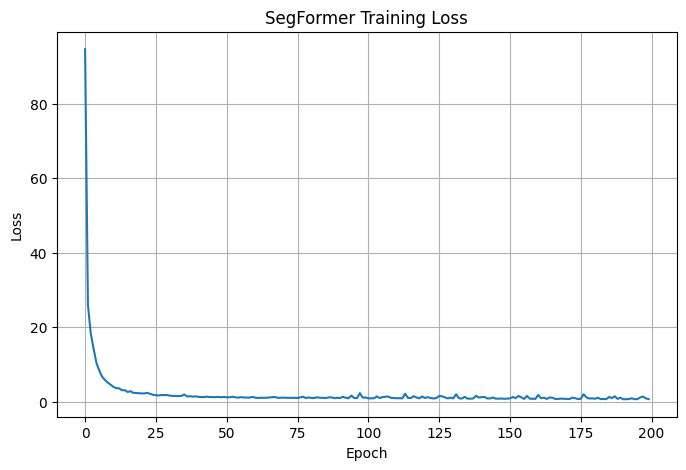

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("SegFormer Training Loss")

plt.grid(True)

plt.show()

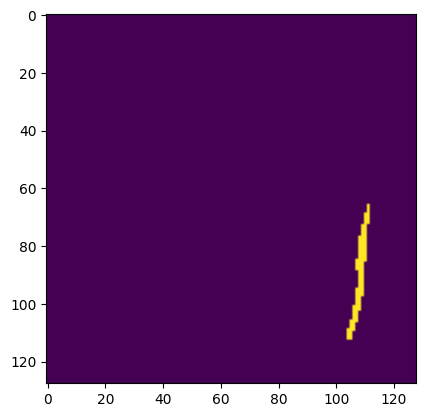

In [36]:
import torch
import numpy as np
from PIL import Image

@torch.no_grad()
def predict(image_path):
    img = Image.open(image_path).convert("RGB")
    inputs = processor(
        images=img,
        return_tensors="pt"
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}
    outputs = model(**inputs)
    logits = outputs.logits
    pred = torch.argmax(logits, dim=1)
    pred = pred.squeeze(0).cpu().numpy()

    return pred
mask = predict("C:/Users/chenk/Desktop/segformer/retina_image/train/images/Stage_1_ROP_1.png")
pred_img = (mask * 255).astype(np.uint8)
plt.imshow(pred_img)

In [12]:
import torch
from torch.optim import AdamW
from transformers import SegformerImageProcessor

processor = SegformerImageProcessor(
    do_resize=True,
    size=512,
    do_normalize=True
)
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

optimizer = AdamW(model.parameters(), lr=6e-5)

model.train()

for epoch in range(60):
    total_loss = 0
    for batch in train_loader:
        optimizer.zero_grad()

        outputs = model(
            pixel_values=batch["pixel_values"].to(device),
            labels=batch["labels"].to(device)
        )

        loss = outputs.loss
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch}: loss = {total_loss:.4f}")
    


KeyboardInterrupt: 

In [ ]:
# import timm
# timm.create_model(
#             'swin_tiny_patch4_window7_224',
#             pretrained=True,
#             features_only=True)
